In [1]:
%matplotlib widget

In [2]:
import numpy as np
from IPython.display import display
import ipywidgets as widgets
from matplotlib import pyplot as plt
from qualang_tools.units import unit
u = unit(coerce_to_integer=True)
from qm.qua import *
from qualang_tools.loops import from_array
import QM
import progress
import time
import h5py

2026-03-03 13:23:28,021 - qm - INFO     - Starting session: c72b1dc6-0f5d-4893-978b-62874c1bf927


# Exercise 1:  Measurement histograms analysis

In [3]:
# Parameters Definition
n_avg = 20000  # The number of averages
thermalization_time = 200 #in µs
waiting_time = 1 * u.us
###################
# The QUA program #
###################
with program() as qmprog:
    n = declare(int)  # QUA variable for the averaging loop
    I0 = declare(fixed)  # QUA variable for the measured 'I' quadrature
    Q0 = declare(fixed)  # QUA variable for the measured 'Q' quadrature
    I0_st = declare_stream()  # Stream for the 'I' quadrature
    Q0_st = declare_stream()  # Stream for the 'Q' quadrature
    I1 = declare(fixed)  # QUA variable for the measured 'I' quadrature
    Q1 = declare(fixed)  # QUA variable for the measured 'Q' quadrature
    I1_st = declare_stream()  # Stream for the 'I' quadrature
    Q1_st = declare_stream()  # Stream for the 'Q' quadrature

    with for_(n, 0, n < n_avg, n + 1):  # QUA for_ loop for averaging
            # Measure the state of the resonator
            # The integration weights have changed to maximize the SNR after having calibrated the IQ blobs.
            measure(
                "readout"*amp(1.4),
                "resonator",
                dual_demod.full("cos", "sin", I0),
                dual_demod.full("minus_sin", "cos", Q0),
            )
            align("qubit", "resonator")
            wait(600*u.ns)
            play("x180"*amp(0.63), "qubit" )
            wait(24*u.ns)
            align("qubit", "resonator")
            # The integration weights have changed to maximize the SNR after having calibrated the IQ blobs.
            measure(
                "readout"*amp(1.4),
                "resonator",
                dual_demod.full("cos", "sin", I1),
                dual_demod.full("minus_sin", "cos", Q1),
            )
            # Wait for the qubit to decay to the ground state
            wait(thermalization_time * u.us, "resonator")
            # Save the 'I' & 'Q' quadratures to their respective streams
            save(I0, I0_st)
            save(Q0, Q0_st)
            save(I1, I1_st)
            save(Q1, Q1_st)

    with stream_processing():
        # Cast the data into a 1D vector, average the 1D vectors together and store the results on the OPX processor
        I0_st.save_all("I0")
        Q0_st.save_all("Q0")
        I1_st.save_all("I1")
        Q1_st.save_all("Q1")

# Send the QUA program to the OPX, which compiles and executes it
job = QM.Job(qmprog)

# Non interacting version
# job = QM.JobSimple(qmprog)
# Wait for the job to finish
# job.wait()

Button(description='Abort', style=ButtonStyle())

Output(outputs=({'output_type': 'stream', 'name': 'stdout', 'text': 'Sending job to qm-1699244890751...'}, {'o…

HTML(value='')

In [4]:
# Fetch results
I0,Q0,I1,Q1=job.get_results("I0", "Q0","I1","Q1")

In [5]:
def rot(I,Q,theta,scale=1e4):
    theta = theta*np.pi/180
    return scale*(I*np.cos(theta)-Q*np.sin(theta)) , scale*(I*np.sin(theta)+Q*np.cos(theta))

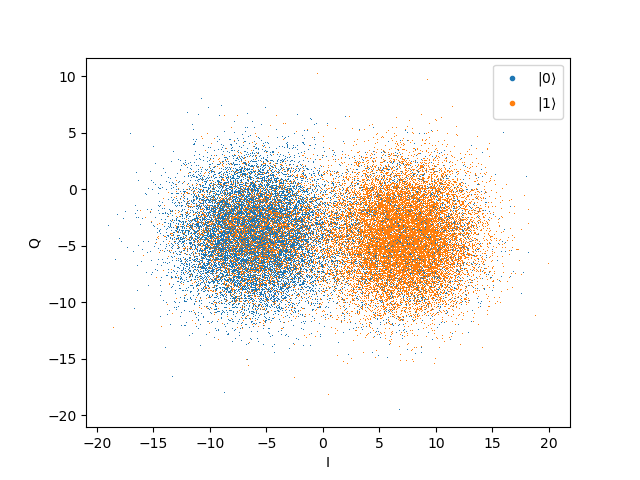

In [7]:
fig,ax = plt.subplots()
I0r, Q0r = rot(I0,Q0,95)
I1r, Q1r = rot(I1,Q1,95)
ax.plot(I0r, Q0r, ',', label=r"$|0\rangle$")
ax.plot(I1r, Q1r, ',', label=r"$|1\rangle$")
ax.set_ylabel("Q")
ax.set_xlabel("I")
legend = ax.legend()
for h in legend.legend_handles:
    h.set_marker(".") 
ax.set_aspect("equal")

- Find the rotation that puts all the information about the qubit state onto $I$.
- Estimate the readout error.
- What is the qubit temperature?

# Exercise 2:  Quantum trajectories

In [8]:
# Parameters Definition
n_meas = 5000  
###################
# The QUA program #
###################
with program() as qmprog:
    n = declare(int)  
    I = declare(fixed)  
    Q = declare(fixed)  
    I_st = declare_stream()  # Stream for the 'I' quadrature
    Q_st = declare_stream()  # Stream for the 'Q' quadrature

    with for_(n, 0, n < n_meas, n + 1):  # QUA for_ loop for averaging
        measure(
            "readout",
            "resonator",
            dual_demod.full("cos", "sin", I),
            dual_demod.full("minus_sin", "cos", Q),
        )
        save(I, I_st)
        save(Q, Q_st)

    with stream_processing():
        # Cast the data into a 1D vector, average the 1D vectors together and store the results on the OPX processor
        I_st.save_all("I")
        Q_st.save_all("Q")

# Send the QUA program to the OPX, which compiles and executes it
job = QM.Job(qmprog)

# Non interacting version
# job = QM.JobSimple(qmprog)
# Wait for the job to finish
# job.wait()

Button(description='Abort', style=ButtonStyle())

Output(outputs=({'output_type': 'stream', 'name': 'stdout', 'text': 'Sending job to qm-1699244890751...'}, {'o…

HTML(value='')

In [9]:
# Fetch results
I,Q=job.get_results("I", "Q")

- From $I$ and $Q$, build a vector of 0s and 1s corresponding to the qubit state over time.
- What is the probability of getting the same result twice in a row?
- What is the probability of getting two different results in a row?
- What is the probability of a jump from state $|0\rangle$ to state $|1\rangle$?
- What is the probability of a jump from state $|1\rangle$ to state $|0\rangle$?
- Relate these two probabilities to the qubit temperature.

# Exercise 3:  Preparation by measurement

In [13]:
# Parameters Definition
n_avg = 500  # The number of averages
# Pulse duration sweep (in clock cycles = 4ns) - must be larger than 4 clock cycles
t_min = 4 // 4
t_max = 1000 // 4
dt = 8 // 4
durations = np.arange(t_min, t_max, dt)

###################
# The QUA program #
###################
with program() as qmprog:
    n = declare(int)  # QUA variable for the averaging loop
    t = declare(int)  # QUA variable for the qubit pulse duration
    I = declare(fixed)  # QUA variable for the measured 'I' quadrature
    Q = declare(fixed)  # QUA variable for the measured 'Q' quadrature
    Z = declare(int) 
    I_st = declare_stream()  # Stream for the 'I' quadrature
    Q_st = declare_stream()  # Stream for the 'Q' quadrature
    with for_(n, 0, n < n_avg, n + 1):  # QUA for_ loop for averaging
        with for_(*from_array(t, durations)):  # QUA for_ loop for sweeping the pulse duration
            # Play the qubit pulse with a variable duration (in clock cycles = 4ns)
            play("pi"*amp(1.0), "qubit", duration=t)
            # Align the two elements to measure after playing the qubit pulse.
            align("qubit", "resonator")
            # Measure the state of the resonator
            measure(
                "readout"*amp(1.4),
                "resonator",
                dual_demod.full("cos", "sin", I),
                dual_demod.full("minus_sin", "cos", Q),
            )
            # Send back qubit to ground state
            assign(Z, Util.cond(Q>2e-4, -1, 1))
            with if_(Z==1):
                play("pi", "qubit", duration=100*u.ns)
                
            save(I, I_st)
            save(Q, Q_st)

    with stream_processing():
        # Cast the data into a 1D vector, average the 1D vectors together and store the results on the OPX processor
        I_st.buffer(len(durations)).average().save("I")
        Q_st.buffer(len(durations)).average().save("Q")      

# Send the QUA program to the OPX, which compiles and executes it
job = QM.Job(qmprog)

# Non interacting version
# job = QM.JobSimple(qmprog)
# Wait for the job to finish
# job.wait()

Button(description='Abort', style=ButtonStyle())

Output(outputs=({'output_type': 'stream', 'name': 'stdout', 'text': 'Sending job to qm-1699244890751...'}, {'o…

HTML(value='')

In [14]:
# Fetch results
I,Q=job.get_results("I", "Q")

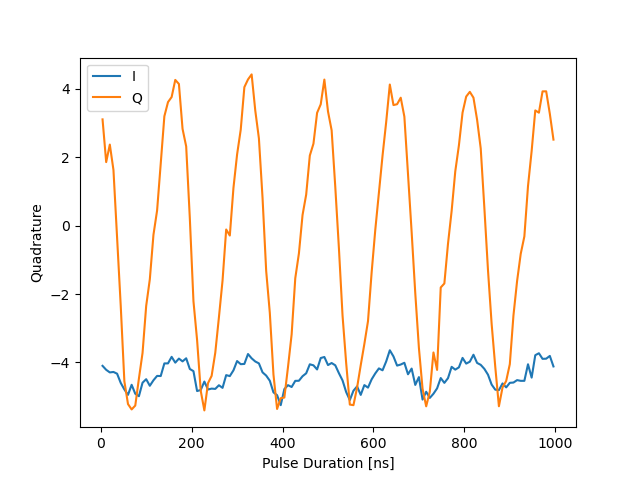

In [15]:
# Create plot
I,Q=job.get_results("I", "Q")
fig,ax = plt.subplots()
ax.plot(4*durations, I*1e4, 4*durations, Q*1e4)
ax.set_ylabel("Quadrature")
ax.set_xlabel("Pulse Duration [ns]")
ax.legend(('I','Q'))

- This sequence allows the measurement of Rabi oscillations. Why is it much faster than the first sequence?
- Verify that the measurement-based state preparation parameters are optimized.
- Modify the sequence so that the QM returns the result of the $Z$ measurement instead of $I$ and $Q$.

# Exercise 4: Rabi Chevrons

- Use the above faster sequence to observe the "Rabi chevrons" by varying the pulse duration and frequency in a double loop.

In [3]:
# Pulse duration sweep (in clock cycles = 4ns) - must be larger than 4 clock cycles

durations =
detuning = 
n_avg = 50
print(len(durations),'x',len(detuning),'x',n_avg)
print(f"Estimated time {sum(durations*4e-9 + 2e-6)*len(detuning)*n_avg:.1f}s")

250 x 200 x 50
Estimated time 7.5s


In [4]:
###################
# The QUA program #
###################
with program() as qmprog:
    n = declare(int)  # QUA variable for the averaging loop
    t = declare(int)  # QUA variable for the qubit pulse duration
    I = declare(fixed)  # QUA variable for the measured 'I' quadrature
    Q = declare(fixed)  # QUA variable for the measured 'Q' quadrature
    fs = declare(int)
    
    Sz = declare(fixed)
    Sz_st = declare_stream()  # Stream for the state
    with for_(n, 0, n < n_avg, n + 1):  # QUA for_ loop for averaging
        with for_(*from_array(fs, detuning)):
            with for_(*from_array(t, durations)):  # QUA for_ loop for sweeping the pulse duration
                # update the qubit frequency
                
                # Play the qubit pulse with a variable duration (in clock cycles = 4ns)
                
                # Align the two elements to measure after playing the qubit pulse.
                
                # Measure the state of the resonator
                measure(
                    "readout"*amp(1.4),
                    "resonator",
                    dual_demod.full("cos", "sin", I),
                    dual_demod.full("minus_sin", "cos", Q),
                )
                # Send back qubit to ground state
                assign(Sz, Util.cond(Q>2e-4, -0.5, 0.5))
                with if_(Q>2e-4):
                    update_frequency('qubit',50000000)
                    play("pi", "qubit", duration=80*u.ns)
                save(Sz, Sz_st)

    with stream_processing():
        # Cast the data into a 1D vector, average the 1D vectors together and store the results on the OPX processor
        Sz_st.buffer(len(durations)).buffer(len(detuning)).buffer(n_avg).map(FUNCTIONS.average(0)).save("Sz")


# Send the QUA program to the OPX, which compiles and executes it
job = QM.Job(qmprog)

Button(description='Abort', style=ButtonStyle())

Output(outputs=({'output_type': 'stream', 'name': 'stdout', 'text': 'Sending job to qm-1699244890751...'}, {'o…

HTML(value='')

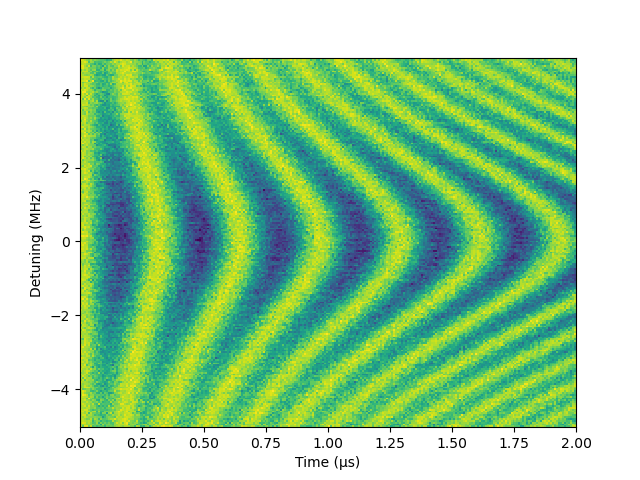

In [13]:
fig,ax=plt.subplots(dpi=100)
Sz, = job.get_results("Sz")
ax.pcolormesh(durations*4e-3,detuning/1e6-50,Sz)
plt.xlabel('Time (µs)')
plt.ylabel('Detuning (MHz)')
#fig.savefig('RabiChevrons.png')
plt.show()

# Exercise 5:  Weak measurement and strong measurement

In [48]:
# Parameters Definition
n_avg = 2000  # The number of averages
# Pulse duration sweep (in clock cycles = 4ns) - must be larger than 4 clock cycles
phase_2_pi = np.linspace(0, 2, 101)

###################
# The QUA program #
###################
with program() as qmprog:
    n = declare(int)  # QUA variable for the averaging loop
    phi = declare(fixed)  # QUA variable for the qubit pulse duration
    I = declare(fixed)  # QUA variable for the measured 'I' quadrature
    Q = declare(fixed)  # QUA variable for the measured 'Q' quadrature
    Z = declare(int) 
    Z_st = declare_stream()  # Stream for the readout

    with for_(n, 0, n < n_avg, n + 1):  # QUA for_ loop for averaging
        with for_(*from_array(phi, phase_2_pi)):  
            play("x90"*amp(0.63), "qubit")
            align("qubit", "resonator")
            play("readout"*amp(0.0),"resonator",duration=1000*u.ns)
            align("qubit", "resonator")
            frame_rotation_2pi(phi,"qubit")
            play("x90"*amp(0.63), "qubit")
            align("qubit", "resonator")
            # Measure the state of the resonator
            measure(
                "readout"*amp(1.6),
                "resonator",
                dual_demod.full("cos", "sin", I),
                dual_demod.full("minus_sin", "cos", Q),
            )
            # Send back qubit to ground state
            assign(Z, Util.cond(Q>2e-4, -1, 1))
            with if_(Z==1):
                play("pi", "qubit", duration=80*u.ns)
                
            save(Z, Z_st)

    with stream_processing():
        # Cast the data into a 1D vector, average the 1D vectors together and store the results on the OPX processor
        Z_st.buffer(len(phase_2_pi)).average().save("Z")

# Send the QUA program to the OPX, which compiles and executes it
job = QM.Job(qmprog)

# Non interacting version
# job = QM.JobSimple(qmprog)
# Wait for the job to finish
# job.wait()

Button(description='Abort', style=ButtonStyle())

Output(outputs=({'output_type': 'stream', 'name': 'stdout', 'text': 'Sending job to qm-1699244890751...'}, {'o…

HTML(value='')

/tmp/ipykernel_30719/1780173348.py:3: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig,ax = plt.subplots()


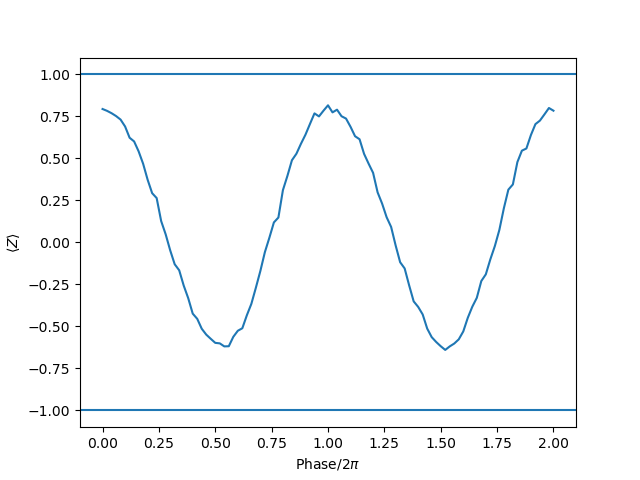

In [49]:
# Get znd plot results
Z, =job.get_results("Z")
fig,ax = plt.subplots()
ax.plot(phase_2_pi, Z)
ax.set_ylabel(r"$\langle Z \rangle$")
ax.set_xlabel(r"Phase/$2\pi$")
ax.axhline(-1)
ax.axhline(1)

- Modify the amplitude of the pulse sent to the resonator (line `play("readout"*amp(0.0),"resonator",duration=1000*u.ns)`). What do you observe?
- Plot the qubit coherence as a function of the resonator pulse amplitude.
- Explain the terms "weak" and "strong" measurement.

# Exercise 5:  Quantum tomography

In [ ]:
# Parameters Definition
n_meas = 5000  
thermalization_time = 200 #in µs

###################
# The QUA program #
###################
with program() as qmprog:
    n = declare(int)  
    I = declare(fixed)  # QUA variable for the measured 'I' quadrature
    Q = declare(fixed)  # QUA variable for the measured 'Q' quadrature
    Z = declare(int) 
    Z_st = declare_stream()  # Stream for the readout


    with for_(n, 0, n < n_meas, n + 1):  # QUA for_ loop for averaging
        play("unknown","qubit") 
        # Do something
        measure(
            "readout",
            "resonator",
            dual_demod.full("cos", "sin", I),
            dual_demod.full("minus_sin", "cos", Q),
        )
        # Send back qubit to ground state
        assign(Z, Util.cond(Q>2e-4, -1, 1))
        with if_(Z==1):
            play("pi", "qubit", duration=100*u.ns)
            
        save(Z, Z_st)

    with stream_processing():
        # Cast the data into a 1D vector, average the 1D vectors together and store the results on the OPX processor
        Z_st.buffer(len(phase_2_pi)).average().save("Z")

# Send the QUA program to the OPX, which compiles and executes it
job = QM.Job(qmprog)

# Non interacting version
# job = QM.JobSimple(qmprog)
# Wait for the job to finish
# job.wait()

- The `unknown` pulse prepares the qubit in an unknown state. Use three different sequences to measure $\langle X \rangle$, $\langle Y \rangle$, and $\langle Z \rangle$ on the unknown state.
- From these, infer the qubit density matrix in the unknown state.